Benjamin Arnold; 10/23/26; Block 2 Checkpoint: Engine Demo

Engine

In [1]:
import numpy as np

#BODY-----------------------------------------
class Body:
    def __init__(self, m=1.0, r=(0.0, 0.0), v=(0.0, 0.0), radius=0.0,
                    fixed=False, name=""):
        self.m, self.radius = float(m), float(radius)
        self.fixed = bool(fixed)
        self.name = name
        
        self.r = np.array(r, dtype=float)
        self.v = np.array(v, dtype=float)
        self.f = np.zeros(2)

    @property
    def inv_m(self):
        return 0.0 if self.fixed else 1.0 / self.m

    def clear(self):
        self.f[:] = 0.0

    def add_force(self, F):
        self.f += np.asarray(F, dtype=float)

    def ke(self):
        return 0.5 * self.m * self.v.dot(self.v)

    def p(self):
        return self.m * self.v

    def __repr__(self):
        return f"Body({self.name}, m={self.m}, r={self.r}, v={self.v})"



#FORCE-------------------------------------------------
class Force:
    def potential_energy(self, world):
        return 0.0

class Gravity(Force):
    def __init__(self, g=9.81):
        self.gmag = g
        self.g    = np.array([0.0, -g])

    def apply(self, world):
        for b in world.bodies:
            if not b.fixed:
                b.add_force(b.m * self.g)

    def potential_energy(self, world):
        return sum(b.m * self.gmag * b.r[1] for b in world.bodies if not b.fixed)

class Spring(Force):
    def __init__(self, i, j, k=1.0, L0=0.0):
        self.i, self.j, self.k, self.L0 = i, j, k, L0

    def length(self, world):
        a, b = world.bodies[self.i], world.bodies[self.j]
        d = b.r - a.r
        return a, b, d, np.linalg.norm(d)
    
    def apply(self, world):
        a, b, d, L = self.length(world)
        if L > 0:
            F = self.k * (L - self.L0) * (d / L)
            a.add_force(F)
            b.add_force(-F)

    def potential_energy(self, world):
        _, _, _, L = self.length(world)
        return 0.5 * self.k * (L - self.L0)**2

class Drag(Force):
    def __init__(self, k=0.1, n=1.0):
        self.k, self.n = k, n
        
    def apply(self, world):
        for b in world.bodies:
            if b.fixed:
                continue
            vmag = np.linalg.norm(b.v)
            if vmag == 0:
                continue
            b.add_force(-self.k*(vmag**self.n)*b.v)



#INTEGRATOR
class EulerCromer:
    name= "Euler Cromer"
    def step(self, world, dt):
        world.compute_forces()
        for b in world.bodies:
            if b.fixed:
                continue
            b.v += (b.f*b.inv_m)*dt
            b.r += b.v*dt

class Euler:
    name = "Euler"
    def step(self, world, dt):
        world.compute_forces()
        for b in world.bodies:
            if b.fixed:
                continue
            a = b.f * b.inv_m
            b.r     += b.v * dt 
            b.v     += a * dt



#WORLD-------------------------------------------
class World:
    def __init__(self, integrator=None, forces=None, bodies=None, constraints=None):
        self.bodies      = list(bodies or [])
        self.forces      = list(forces or [])
        self.constraints = list(constraints or [])
        self.integrator  = integrator
        self.t           = 0.0
        self.recorders   = {}
        self.history     = {}

    def add(self, body):
        self.bodies.append(body); return body

    def add_force(self, force):
        self.forces.append(force); return force

    def add_constraint(self, c):
        self.constraints.append(c); return c

    def compute_forces(self):
        for b in self.bodies:
            b.clear()
        for f in self.forces:
            f.apply(self)                  

    def step(self, dt):
        self.integrator.step(self, dt)      
        for c in self.constraints:          
            c.resolve(self)
        self.t += dt                              

    
    def kinetic_energy(self):
        return sum(b.ke() for b in self.bodies)
    def potential_energy(self):
        return sum(f.potential_energy(self) for f in self.forces)
    def total_energy(self):
        return self.kinetic_energy() + self.potential_energy()
    def momentum(self):
        return sum((b.p() for b in self.bodies), np.zeros(2))

    
    def record(self, name, fn):
        self.recorders[name] = fn
        self.history[name]   = []

    def capture(self):
        for k, fn in self.recorders.items():
            self.history[k].append(fn(self))

    def run(self, dt, t_end):
        self.capture()
        for _ in range(int(round(t_end / dt))):
            self.step(dt)
            self.capture()
        return {k: np.array(v) for k, v in self.history.items()}



#CONSTRAINTS-------------------------------------------------------
def resolve_pair(a, b, e=1.0):
    d    = b.r - a.r
    dist = np.linalg.norm(d)
    if dist == 0 or dist > a.radius + b.radius:
        return False                      

    n     = d / dist                      
    v_rel = b.v - a.v
    vn    = v_rel.dot(n)
    if vn > 0:
        return False                     

    im_a, im_b = a.inv_m, b.inv_m
    if im_a + im_b == 0:
        return False                      

    J = -(1 + e) * vn / (im_a + im_b)    
    a.v -= J * im_a * n
    b.v += J * im_b * n

    overlap = a.radius + b.radius - dist  
    a.r -= n * overlap * (im_a / (im_a + im_b))
    b.r += n * overlap * (im_b / (im_a + im_b))
    return True


class CircleCollisions:
    def __init__(self, e=1.0):
        self.e = e
        self.count = 0
    def resolve(self, world):
        bs = world.bodies
        for i in range(len(bs)):
            for j in range(i + 1, len(bs)):
                if bs[i].radius > 0 and bs[j].radius > 0:
                    if resolve_pair(bs[i], bs[j], self.e):
                        self.count += 1


class BoxWalls:
    def __init__(self, xmin, xmax, ymin, ymax, e=1.0):
        self.bounds = (xmin, xmax, ymin, ymax)
        self.e = e
        self.count = 0
    def resolve(self, world):
        xmin, xmax, ymin, ymax = self.bounds
        for b in world.bodies:
            if b.fixed:
                continue
            R = b.radius
            if b.r[0] - R < xmin:
                b.r[0] = xmin + R; b.v[0] = -self.e * b.v[0]; self.count += 1
            if b.r[0] + R > xmax:
                b.r[0] = xmax - R; b.v[0] = -self.e * b.v[0]; self.count += 1
            if b.r[1] - R < ymin:
                b.r[1] = ymin + R; b.v[1] = -self.e * b.v[1]; self.count += 1
            if b.r[1] + R > ymax:
                b.r[1] = ymax - R; b.v[1] = -self.e * b.v[1]; self.count += 1

Demo

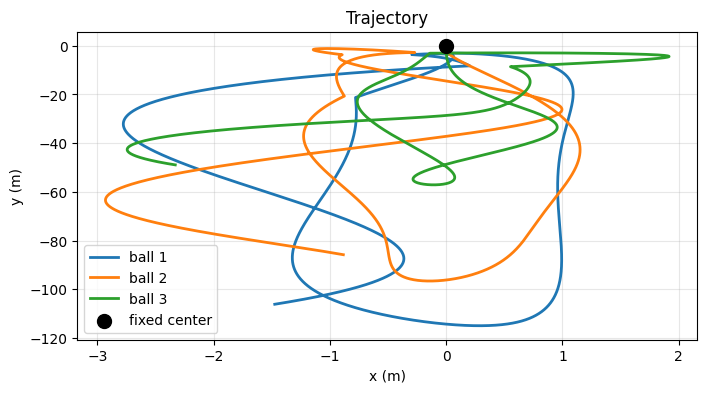

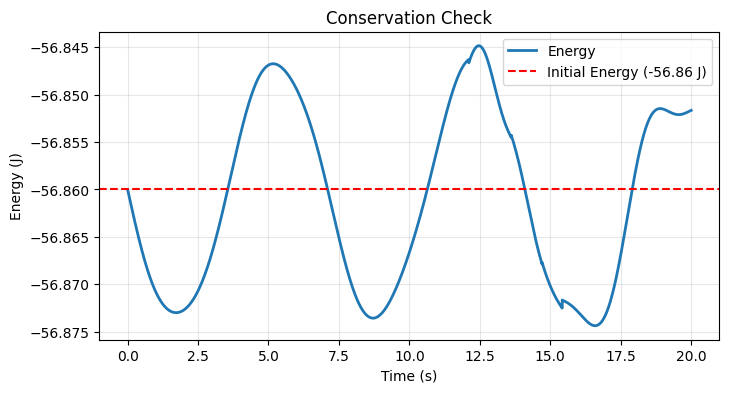

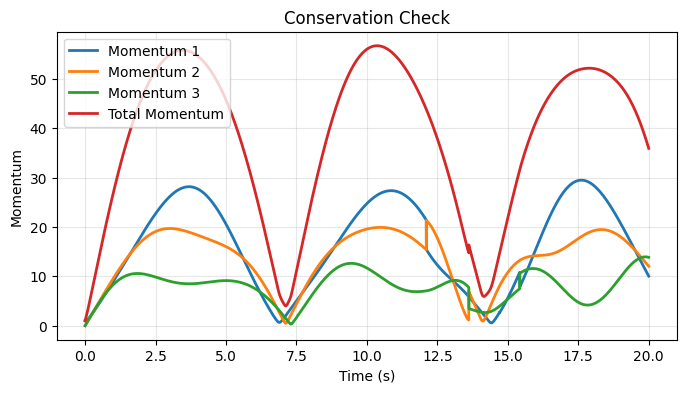

In [23]:
import matplotlib.pyplot as plt

world=World(integrator=EulerCromer(), constraints=[CircleCollisions(e=1)])
world.add(Body(m=1.0, r=(0, -3), v=(1,0), radius=0.4))
world.add(Body(m=1.0, r=(0, -2), v=(0,0), radius=0.2))
world.add(Body(m=1.0, r=(0, -1), v=(0,0), radius=0.1))
world.add(Body(m=1.0, r=(0, 0), fixed=True))

world.add_force(Spring(0,1))
world.add_force(Spring(1,2))
world.add_force(Spring(2,3))
world.add_force(Gravity())

world.record('t', lambda W: W.t)
world.record('r1', lambda W: np.array(W.bodies[0].r))
world.record('r2', lambda W: np.array(W.bodies[1].r))
world.record('r3', lambda W: np.array(W.bodies[2].r))
world.record('v1', lambda W: np.array(W.bodies[0].v))
world.record('v2', lambda W: np.array(W.bodies[1].v))
world.record('v3', lambda W: np.array(W.bodies[2].v))
world.record('E', lambda W: np.array(W.total_energy()))

w=world.run(dt=0.0001,t_end=20)

t = np.array(world.history['t'])
E = np.array(world.history['E'])

r1 = np.array(world.history['r1'])
r2 = np.array(world.history['r2'])
r3 = np.array(world.history['r3'])
v1 = np.array(world.history['v1'])
v2 = np.array(world.history['v2'])
v3 = np.array(world.history['v3'])

sp1=np.linalg.norm(v1, axis=1)
sp2=np.linalg.norm(v2, axis=1)
sp3=np.linalg.norm(v3, axis=1)



plt.figure(figsize=(8, 4))
plt.plot(r1[:,0], r1[:,1], linewidth=2, label='ball 1')
plt.plot(r2[:,0], r2[:,1], linewidth=2, label='ball 2')
plt.plot(r3[:,0], r3[:,1], linewidth=2, label='ball 3')
plt.scatter(0, 0, color='black', s=100, zorder=5, label='fixed center')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Trajectory')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, E, linewidth=2, label='Energy')
plt.axhline(y=E[0], color='red', linestyle='--', linewidth=1.5, label=f'Initial Energy ({E[0]:.2f} J)')
plt.xlabel('Time (s)')
plt.ylabel('Energy (J)')
plt.title('Conservation Check')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, sp1, linewidth=2, label='Momentum 1')
plt.plot(t, sp2, linewidth=2, label='Momentum 2')
plt.plot(t, sp3, linewidth=2, label='Momentum 3')
plt.plot(t, sp1+sp2+sp3, linewidth=2, label='Total Momentum')
plt.xlabel('Time (s)')
plt.ylabel('Momentum')
plt.title('Conservation Check')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()